# Counterfeit Banknote Classification

We're going to work with the fake bill dataset. The dataset examine whether the bill is fraudulent based on its dimensions.

In [28]:
# install package in Colab
! pip install wget

In [29]:
import wget
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 0: Getting started

First off, load the dataset in CSV file as a Pandas DataFrame and name it df. Print out the first few rows of the dataset, and take a look at the features data and the target columns.

In [30]:
myfile = wget.download('https://saref.github.io/teaching/MIE1626/modified_fake_bills_csv.csv')

In [31]:
df = pd.read_csv(myfile)
df # 1500 rows * 7 columns

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,515.43,104.86,104.95,4.52,2.89,112.83
1,True,514.38,103.36,103.66,3.77,2.99,113.09
2,True,518.07,104.48,103.50,4.40,2.94,113.16
3,True,514.08,103.91,103.94,3.62,3.01,113.51
4,True,515.19,104.28,103.46,4.04,3.48,112.54
...,...,...,...,...,...,...,...
1495,False,515.25,104.38,104.17,4.42,3.09,111.28
1496,False,516.57,104.63,104.44,5.27,3.37,110.97
1497,False,515.40,104.01,104.12,5.51,3.36,111.95
1498,False,516.18,104.28,104.06,5.17,3.46,112.25


In [32]:
df.head() # 6 features, the target column is 'is_genuine'

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,515.43,104.86,104.95,4.52,2.89,112.83
1,True,514.38,103.36,103.66,3.77,2.99,113.09
2,True,518.07,104.48,103.50,4.40,2.94,113.16
3,True,514.08,103.91,103.94,3.62,3.01,113.51
4,True,515.19,104.28,103.46,4.04,3.48,112.54


Add an additional column containing either 1 (if the target col is True) or 0 (if the target col is False). This will be the new target value to classify the data.

In [33]:
df['target'] = df['is_genuine'].astype(int)
df['target'].value_counts() # imbalanced

,count
target,
1,1000
0,500


In [34]:
df

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length,target
0,True,515.43,104.86,104.95,4.52,2.89,112.83,1
1,True,514.38,103.36,103.66,3.77,2.99,113.09,1
2,True,518.07,104.48,103.50,4.40,2.94,113.16,1
3,True,514.08,103.91,103.94,3.62,3.01,113.51,1
4,True,515.19,104.28,103.46,4.04,3.48,112.54,1
...,...,...,...,...,...,...,...,...
1495,False,515.25,104.38,104.17,4.42,3.09,111.28,0
1496,False,516.57,104.63,104.44,5.27,3.37,110.97,0
1497,False,515.40,104.01,104.12,5.51,3.36,111.95,0
1498,False,516.18,104.28,104.06,5.17,3.46,112.25,0


In [35]:
features = df.drop(columns=['is_genuine','target'])
features # Features are the physical measurements of a single banknote

,diagonal,height_left,height_right,margin_low,margin_up,length
0,515.43,104.86,104.95,4.52,2.89,112.83
1,514.38,103.36,103.66,3.77,2.99,113.09
2,518.07,104.48,103.50,4.40,2.94,113.16
3,514.08,103.91,103.94,3.62,3.01,113.51
4,515.19,104.28,103.46,4.04,3.48,112.54
...,...,...,...,...,...,...
1495,515.25,104.38,104.17,4.42,3.09,111.28
1496,516.57,104.63,104.44,5.27,3.37,110.97
1497,515.40,104.01,104.12,5.51,3.36,111.95
1498,516.18,104.28,104.06,5.17,3.46,112.25


In [36]:
target = df["target"]
target

,target
0,1
1,1
2,1
3,1
4,1
...,...
1495,0
1496,0
1497,0
1498,0


# Part A: Pre-processing

# Part A1: Data Cleaning

Check if there are missing values in the dataset. Report the total number of missing values and the number of rows containing them, then delete all rows containing missing values

In [37]:
missing_per_column = df.isnull().sum()
total_missing_values = missing_per_column.sum()
columns_with_missing_values = df.isnull().any(axis=0).sum()
rows_with_missing_values = df.isnull().any(axis=1).sum()
print(f"Missing per column: \n{missing_per_column}")
print(f"\nTotal missing values: {total_missing_values}")
print(f"\nColumns with missing values: {columns_with_missing_values}")
print(f"\nRows with missing values: {rows_with_missing_values}")

Missing per column: 
is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
target           0
dtype: int64

Total missing values: 37

Columns with missing values: 1

Rows with missing values: 37


In [38]:
df = df.dropna().reset_index(drop=True)
df

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length,target
0,True,515.43,104.86,104.95,4.52,2.89,112.83,1
1,True,514.38,103.36,103.66,3.77,2.99,113.09,1
2,True,518.07,104.48,103.50,4.40,2.94,113.16,1
3,True,514.08,103.91,103.94,3.62,3.01,113.51,1
4,True,515.19,104.28,103.46,4.04,3.48,112.54,1
...,...,...,...,...,...,...,...,...
1458,False,515.25,104.38,104.17,4.42,3.09,111.28,0
1459,False,516.57,104.63,104.44,5.27,3.37,110.97,0
1460,False,515.40,104.01,104.12,5.51,3.36,111.95,0
1461,False,516.18,104.28,104.06,5.17,3.46,112.25,0


In [39]:
remaining_missing_values = df.isnull().sum().sum()
remaining_missing_values

np.int64(0)

# Part A2: Clean Up the DataFrame

Keep the feature columns for the X value.


In [40]:
features = df.drop(columns=['is_genuine','target'])
X = features
X

,diagonal,height_left,height_right,margin_low,margin_up,length
0,515.43,104.86,104.95,4.52,2.89,112.83
1,514.38,103.36,103.66,3.77,2.99,113.09
2,518.07,104.48,103.50,4.40,2.94,113.16
3,514.08,103.91,103.94,3.62,3.01,113.51
4,515.19,104.28,103.46,4.04,3.48,112.54
...,...,...,...,...,...,...
1458,515.25,104.38,104.17,4.42,3.09,111.28
1459,516.57,104.63,104.44,5.27,3.37,110.97
1460,515.40,104.01,104.12,5.51,3.36,111.95
1461,516.18,104.28,104.06,5.17,3.46,112.25


In [41]:
target = df["target"]
y = target
y

,target
0,1
1,1
2,1
3,1
4,1
...,...
1458,0
1459,0
1460,0
1461,0


# Part A3: Data Splitting

It is best practice to have a training set (from which there is a rotating validation subset) and a test set. Our aim here is to (eventually) obtain the best accuracy we can on the test set (we'll do all our tuning on the training/validation sets, however.)

Split the dataset into a training and a test set "70:30", use `random_state=21`. The test set is set aside (untouched) for final evaluation in Part E after hyperparameter optimization is complete.

In [42]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=21)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (1024, 6)
X_test shape: (439, 6)
y_train shape: (1024,)
y_test shape: (439,)


# Part A4: Effect of Standardization (Visual)

Use seaborn.lmplot to visualize the following two features of the training set: draw a plot where the x-axis is the height_left, and the y-axis is the diagonal, and the color of each datapoint indicates its class.

Standardizing the data is sometimes critical in machine learning (especially for distance-based methods). Show a new plot as above, but standardize the two features.

In [43]:
import seaborn as sns
from sklearn import preprocessing

<function matplotlib.pyplot.show(close=None, block=None)>

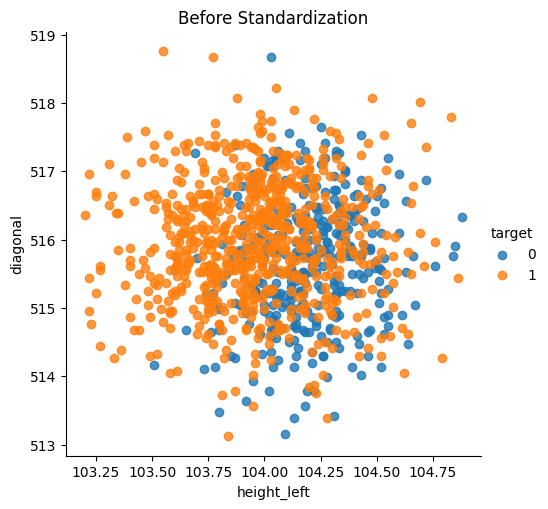

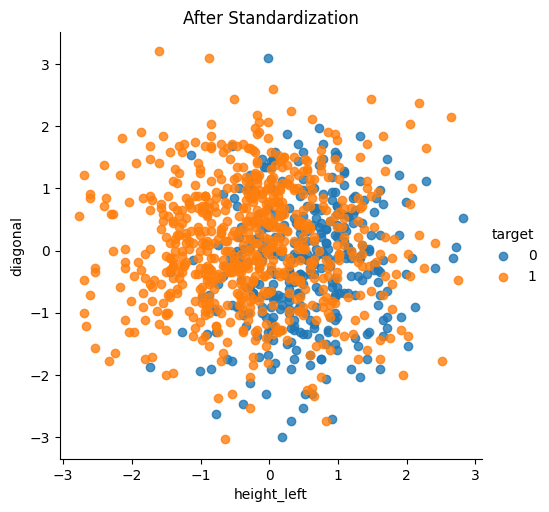

In [44]:
# Raw data
train_df = X_train.copy()
train_df['target'] = y_train

sns.lmplot(
    data = train_df,
    x = 'height_left',
    y = 'diagonal',
    hue = 'target',
    fit_reg = False, # turn off regression line
)
plt.title('Before Standardization')
plt.show

# Standardized data
feature_to_scale = ['height_left', 'diagonal']
scaler = preprocessing.StandardScaler()

train_df_scaled = train_df.copy()
train_df_scaled[feature_to_scale] = scaler.fit_transform(train_df[feature_to_scale])

sns.lmplot(
    data = train_df_scaled,
    x = 'height_left',
    y = 'diagonal',
    hue = 'target',
    fit_reg = False,
)
plt.title('After Standardization')
plt.show

After standardization, both features are centered around 0, with most values falling between -3 and +3 standard deviations.

**Why do they look similar?** Standardization applies a linear transformation to each feature using the formula z = (x - mean) / standard deviation. Subtracting the mean shifts the values, while dividing by the standard deviation changes their scales. This preserves the relative ordering and linear relationships of the data points, so the overall patterns remain similar. However, the distances between points can change.

**Advantage of standardization:** Features in a dataset may have different numerical scales and variances. Distance-based algorithms, such as KNN and SVM with an RBF kernel, can be sensitive to these differences because features with larger numerical ranges may dominate distance calculations. Standardization places features on comparable scales, with a mean of 0 and a variance of 1. This reduces the influence of scale differences and can improve the performance of scale-sensitive models.

# Part B: KNN

# Part B1: KNN Classifier with Standardization

1. Standardize the training and test data.
2. Train a KNN Classifier using 5-fold cross-validation on the standardized training set. Sweep k (number of neighbours) from 1 to 600 with a step size of 1, and show a plot of the mean cross-validation accuracy vs k. Include standard deviation of the cross-validation accuracy as error bars on the chart.
3. Find the best k and the highest cross-validation accuracy.
4. Repeat the same KNN procedure (5-fold cross-validation and a k sweep from 1 to 600 with a step size of 1) using the original (unstandardized) training set. Compare the best cross-validation performance with that obtained using the standardized features.

In [45]:
from sklearn import neighbors
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.pipeline import make_pipeline

In [46]:
# Standardization
scaler = preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
# KNN with 5-fold CV
B1_k_range = range(1, 601)

def evaluate_knn(X_data, y_data, standardize=False):
    mean_acc = []
    std_acc = []
    train_acc = []

    for k in B1_k_range:
        if standardize:
            model = make_pipeline(
                preprocessing.StandardScaler(),
                neighbors.KNeighborsClassifier(n_neighbors=k)
            )
        else:
            model = neighbors.KNeighborsClassifier(n_neighbors=k)

        scores = cross_validate(
            model, X_data, y_data,
            cv=5,
            scoring='accuracy',
            return_train_score=True,
            n_jobs=-1
        )

        mean_acc.append(scores['test_score'].mean())
        std_acc.append(scores['test_score'].std())
        train_acc.append(scores['train_score'].mean())

    return np.array(mean_acc), np.array(std_acc), np.array(train_acc)


# Standardized
scaled_mean, scaled_std, scaled_train_mean = evaluate_knn(
    X_train, y_train, standardize=True
)

# Unstandardized
original_mean, original_std, original_train_mean = evaluate_knn(
    X_train, y_train, standardize=False
)

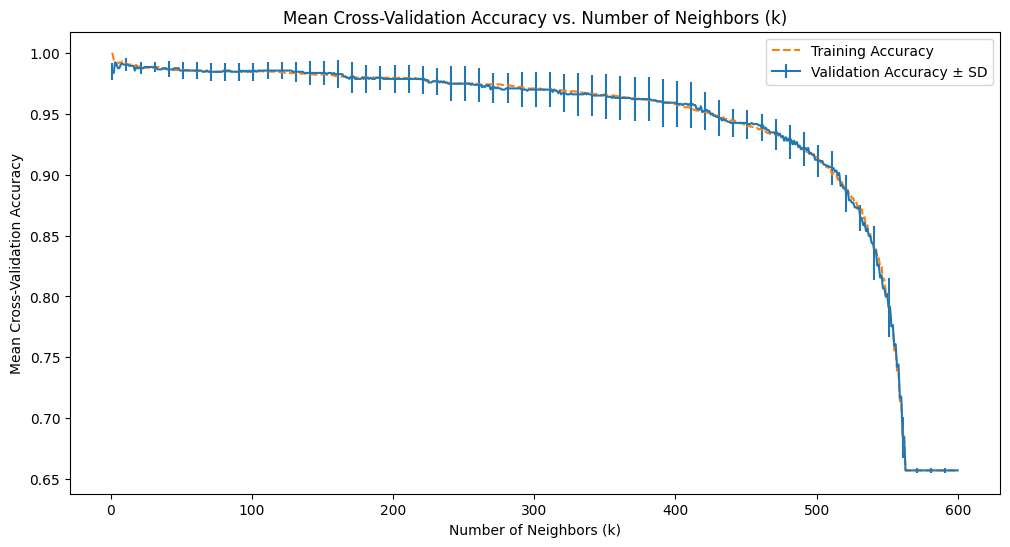

In [48]:
# Standardized
plt.figure(figsize=(12,6))
plt.errorbar(
    x = B1_k_range,
    y = scaled_mean,
    yerr = scaled_std,
    fmt = '-',
    errorevery = 10,
    label = 'Validation Accuracy ± SD'
)
plt.plot(
    B1_k_range,
    scaled_train_mean,
    linestyle = '--',
    label= 'Training Accuracy'
)
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('Mean Cross-Validation Accuracy vs. Number of Neighbors (k)')
plt.legend()
plt.show()

In [49]:
best_index_scaled = np.argmax(scaled_mean)
best_k_scaled = B1_k_range[best_index_scaled]
best_accuracy_scaled = scaled_mean[best_index_scaled]

print(f'Best K (Standardized): {best_k_scaled}')
print(f'Best Accuracy (Standardized): {best_accuracy_scaled:.9f}')

best_index_original = np.argmax(original_mean)
best_k_original = B1_k_range[best_index_original]
best_accuracy_original = original_mean[best_index_original]

print(f'Best K (Unstandardized): {best_k_original}')
print(f'Best Accuracy (Unstandardized): {best_accuracy_original:.9f}')

Best K (Standardized): 3
Best Accuracy (Standardized): 0.992185557
Best K (Unstandardized): 8
Best Accuracy (Unstandardized): 0.990243902


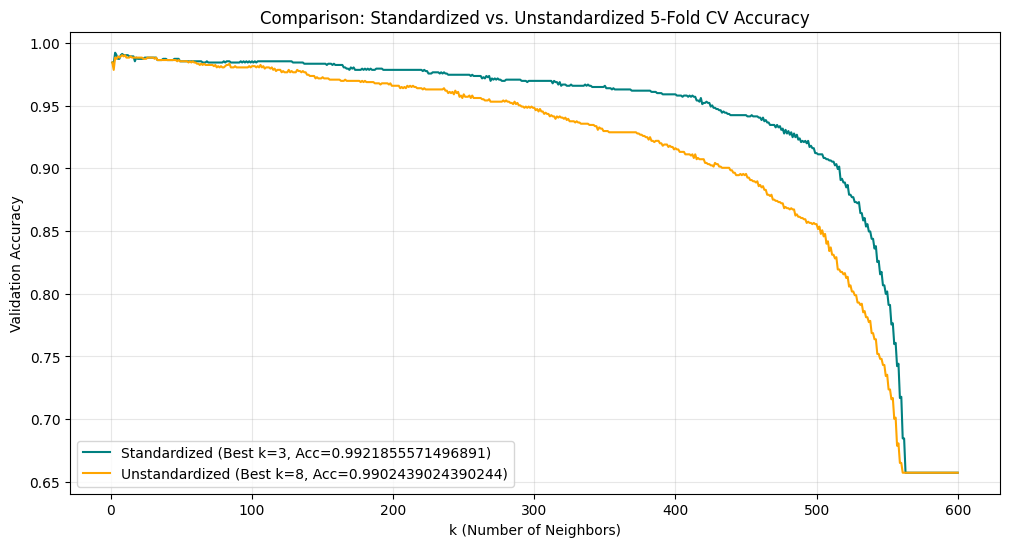

In [50]:
plt.figure(figsize=(12, 6))
plt.plot(
    B1_k_range,
    scaled_mean,
    color='teal',
    label=f'Standardized (Best k={best_k_scaled}, Acc={best_accuracy_scaled})'
)
plt.plot(
    B1_k_range,
    original_mean,
    color='orange',
    label=f'Unstandardized (Best k={best_k_original}, Acc={best_accuracy_original})'
)
plt.title('Comparison: Standardized vs. Unstandardized 5-Fold CV Accuracy')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Validation Accuracy')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

In [51]:
difference = best_accuracy_scaled - best_accuracy_original
print(f"Accuracy Difference: {difference * 100:.2f} percentage points")

Accuracy Difference: 0.19 percentage points


 Using standardized features, the best k is **3**, achieving the highest mean validation accuracy of **0.992185557 (99.22%)**.

 For very small k values, especially k = 1, the model achieves nearly perfect training accuracy while validation accuracy is lower, indicating **overfitting**. Around k = 3, validation accuracy reaches its highest value, suggesting a good balance between fitting the training data and generalizing to new data. As k increases, both training and validation accuracies gradually decrease, indicating increasing **underfitting**. This becomes especially noticeable for k above approximately 400, where the model considers too many neighbors and loses its ability to distinguish between classes.

 **Performance Comparison:** Using unstandardized features, the best k is **8**, with a highest mean validation accuracy of **0.990243902 (99.02%)**. The standardized model achieves a slightly higher peak accuracy, improving by 0.20 percentage points. The comparison plot also shows that standardized KNN generally maintains higher validation accuracy across larger values of k.

**Effect of Standardization:** KNN uses distances between samples to make predictions. Without standardization, features with larger numerical variation may have a greater influence on the distance calculations. Standardization places all features on comparable scales, reducing this imbalance. In this experiment, standardization slightly improves the highest validation accuracy and maintains better performance across a wider range of k values.

# Part B2: Forward Feature Selection

In this part, we will investigate a feature-selection approach using Forward Selection.

Forward selection is a greedy selection procedure. At each step, it augments the current feature set by including one additional feature. The selected feature is the one that gives the best model performance when added to the features already selected.

Procedure:

1. Begin by evaluating each individual feature using a KNN classifier with 5-fold cross-validation, tune k from 1 to 100 with a step size of 1, and select the feature that gives the highest cross-validation accuracy.
2. Add each remaining features to the current selected feature set one at a time as a candidate.
3. For each candidate addition, tune k over the same range used in Part B1 using 5-fold cross-validation.
4. Select the candidate feature that gives the highest mean cross-validation accuracy and add it to the selected feature set.
5. The code records and prints the selected feature, the best mean cross-validation accuracy, and the corresponding k.
6. Repeat Steps 2-5 until all features have been added.

(Apply forward selection to the standardized training data.)

In [52]:
B2_feature_names = X_train.columns.tolist()
B2_k_range_first = range(1, 101)
B2_k_range_later = range(1, 601)

In [53]:
# Evaluate each candidate feature subset using 5-fold CV
def evaluate_feature_subset(feature_subset, k_range):
    X_subset = X_train[feature_subset]
    best_accuracy = -1
    best_k = None

    for k in k_range:
        model = make_pipeline(
            preprocessing.StandardScaler(),
            neighbors.KNeighborsClassifier(n_neighbors=k)
        )

        scores = cross_val_score(
            model, X_subset, y_train,
            cv=5, scoring='accuracy',
            n_jobs=-1
        )
        mean_accuracy = scores.mean()

        if mean_accuracy > best_accuracy:
            best_accuracy = mean_accuracy
            best_k = k

    return best_accuracy, best_k

In [54]:
# Greedy forward selection
remaining_features = B2_feature_names.copy()
selected_features = []

B2_accuracy = []
B2_best_k = []
B2_selected_features = []

for step in range(1, len(B2_feature_names) + 1):
    best_feature = None
    best_accuracy = -1
    best_k = None

    # First feature: k=1–100; remaining features: k=1–600
    k_range = B2_k_range_first if step == 1 else B2_k_range_later

    for feature in remaining_features:
        candidate_features = selected_features + [feature]

        accuracy, k = evaluate_feature_subset(
            candidate_features, k_range
        )

        if accuracy > best_accuracy:
            best_feature = feature
            best_accuracy = accuracy
            best_k = k

    selected_features.append(best_feature)
    remaining_features.remove(best_feature)

    B2_accuracy.append(best_accuracy)
    B2_best_k.append(best_k)
    B2_selected_features.append(selected_features.copy())

    print(
        f'Step {step}: Added "{best_feature}"; '
        f'Best k: {best_k}; '
        f'Highest Mean CV Accuracy: {best_accuracy:.9f}'
    )

Step 1: Added "length"; Best k: 58; Highest Mean CV Accuracy: 0.958034433
Step 2: Added "margin_low"; Best k: 4; Highest Mean CV Accuracy: 0.986341463
Step 3: Added "margin_up"; Best k: 6; Highest Mean CV Accuracy: 0.990243902
Step 4: Added "height_left"; Best k: 3; Highest Mean CV Accuracy: 0.991219512
Step 5: Added "diagonal"; Best k: 6; Highest Mean CV Accuracy: 0.992195122
Step 6: Added "height_right"; Best k: 3; Highest Mean CV Accuracy: 0.992185557


In [55]:
# Find the optimal feature subset
best_index = np.argmax(B2_accuracy)

best_num_features = best_index + 1
best_feature_subset = B2_selected_features[best_index]
best_accuracy = B2_accuracy[best_index]
best_k = B2_best_k[best_index]

print(f'Optimal Number of Features: {best_num_features}')
print(f'Optimal Feature Subset: {best_feature_subset}')
print(f'Highest Mean CV Accuracy: {best_accuracy:.9f}')
print(f'Corresponding Best k: {best_k}')

Optimal Number of Features: 5
Optimal Feature Subset: ['length', 'margin_low', 'margin_up', 'height_left', 'diagonal']
Highest Mean CV Accuracy: 0.992195122
Corresponding Best k: 6


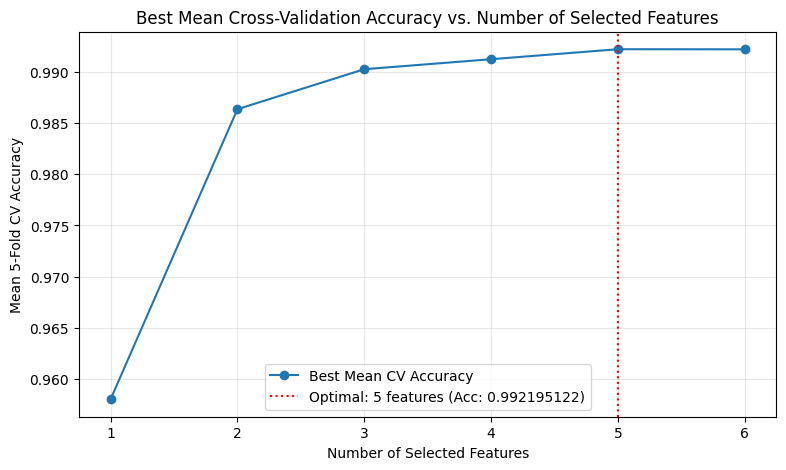

In [56]:
# Plot accuracy vs. number of selected features
B2_feature_range = range(1, len(B2_feature_names) + 1)

plt.figure(figsize=(9, 5))
plt.plot(
    B2_feature_range,
    B2_accuracy,
    marker='o',
    label='Best Mean CV Accuracy'
)
plt.axvline(
    best_num_features,
    color='red',
    linestyle=':',
    label=f'Optimal: {best_num_features} features '
          f'(Acc: {best_accuracy:.9f})'
)
plt.xlabel('Number of Selected Features')
plt.ylabel('Mean 5-Fold CV Accuracy')
plt.title('Best Mean Cross-Validation Accuracy vs. Number of Selected Features')
plt.xticks(B2_feature_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

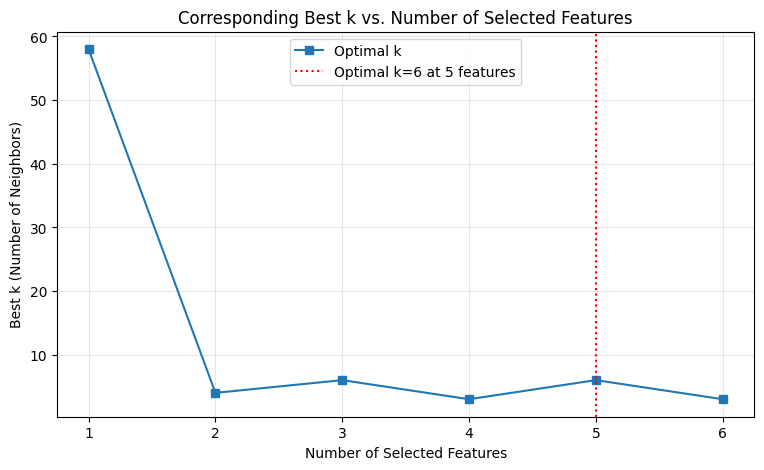

In [57]:
# Plot best k vs. number of selected features
plt.figure(figsize=(9, 5))
plt.plot(
    B2_feature_range,
    B2_best_k,
    marker='s',
    label='Optimal k'
)
plt.axvline(
    best_num_features,
    color='red',
    linestyle=':',
    label=f'Optimal k={best_k} at {best_num_features} features'
)
plt.xlabel('Number of Selected Features')
plt.ylabel('Best k (Number of Neighbors)')
plt.title('Corresponding Best k vs. Number of Selected Features')
plt.xticks(B2_feature_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

I plot the best mean 5-fold CV accuracy against the number of selected features. The accuracy increases from **0.958034433** with only length to **0.986341463** after adding `margin_low`. It continues to improve as more features are added, reaching its highest value of **0.992195122 (99.22%)** with five features. Adding the sixth feature `height_right`, slightly decreases the accuracy to **0.992185557**, so the **five-feature** subset is selected.

I plot the corresponding best k against the number of selected features. With only `length`, the best k is **58**. After adding `margin_low`, it decreases to **4**. For the remaining steps, the best k stays between **3 and 6**. This shows that the optimal number of neighbors depends on the selected feature subset.

The optimal subset contains 5 features: `length`, `margin_low`, `margin_up`, `height_left`, `diagonal`. It achieves a highest mean 5-fold CV accuracy of **0.992195122 (99.22%)**, with the corresponding best **k = 6**.

# Part B3: Tree-based Feature Selector Function

In this part, we aim to investigate the importance of each feature on the final classification accuracy. If we want to try every possible combination of features, we would have to test $2^F$ different cases, where F is the number of features, and in each case, we have to do a hyperparameter search (finding K, in KNN using cross-validation). That will take days!

To find more important features we will use a decision tree to compute feature importance that is a metric for our feature selection.

After we identified and removed the least important feature and evaluated a new KNN model on the new set of features, if the stop conditions are not met, we need to repeat the process and remove another feature.

### The 8-step process for creating the Tree-based Feature_selector function
Design a function (`Feature_selector`) that accepts dataset (X_train , y_train) and a threshold as inputs and:

1. Fits a decision tree classifier on the training set.

2. Extracts the feature importance order of the decision tree model.

3. Removes the least important feature based on step 2.

4. Then, a KNN model is trained on the remaining features. The number of neighbors k for each KNN model should be tuned from 1 to 100 with a step size of 1 using a 5-fold cross-validation.

5. Store the best mean cross-validation score and the corresponding k (number of neighbours) value in two lists.

6. Go back to step 3 and follow all the steps until meet the stop condition (step 7).

7. We will stop this process when (1) there is only one feature left, or (2) our cross-validation accuracy is dropped significantly compared to a model that uses all the features. In this function, we accept a threshold as an input argument. For example, if threshold=0.95 we do not continue removing features if our mean cross-validation accuracy after tuning k is bellow **0.95  $\times$  Full Feature cross-validation accuracy**.

8. The function returns the list of removed features, and the corresponding mean cross-validation accuracy and k value when a feature was removed.




In [59]:
from sklearn import tree

# Define Tree-based Feature Selector
def Feature_selector(X_data, y_data, threshold=0.95):

    current_features = X_data.columns.tolist()
    B3_k_range = range(1, 101)

    # Evaluate KNN using 5-fold CV
    def evaluate_knn(feature_subset):
        X_subset = X_data[feature_subset]

        best_accuracy = -1
        best_k = None
        best_std = None

        for k in B3_k_range:
            model = make_pipeline(
                preprocessing.StandardScaler(),
                neighbors.KNeighborsClassifier(
                    n_neighbors=k, n_jobs=-1
                )
            )

            scores = cross_val_score(
                model, X_subset, y_data,
                cv=5, scoring='accuracy',
                n_jobs=-1
            )

            mean_accuracy = scores.mean()

            if mean_accuracy > best_accuracy:
                best_accuracy = mean_accuracy
                best_k = k
                best_std = scores.std()

        return best_accuracy, best_k, best_std

    # Evaluate the full-feature model
    full_accuracy, full_k, full_std = evaluate_knn(
        current_features
    )
    threshold_accuracy = threshold * full_accuracy

    # Rank features using Decision Tree
    dt = tree.DecisionTreeClassifier(random_state=21)
    dt.fit(X_data, y_data)

    importance = dt.feature_importances_
    sorted_index = np.argsort(importance)
    importance_order = [current_features[i] for i in sorted_index]

    # Remove features from least to most important
    removed_features = []
    B3_accuracy = []
    B3_best_k = []
    B3_std = []
    B3_feature_subsets = []

    stop_reason = "One feature remains"
    rejected_removal = None

    for feature in importance_order:
        if len(current_features) <= 1:
            break

        candidate_features = [
            f for f in current_features if f != feature
        ]

        accuracy, k, std = evaluate_knn(candidate_features)

        # Stop if accuracy drops below threshold
        if accuracy < threshold_accuracy:
            stop_reason = "Accuracy below threshold"
            rejected_removal = feature
            break

        current_features = candidate_features
        removed_features.append(feature)

        B3_accuracy.append(accuracy)
        B3_best_k.append(k)
        B3_std.append(std)
        B3_feature_subsets.append(current_features.copy())

        print(
            f'Removed "{feature}"; '
            f'Remaining features: {len(current_features)}; '
            f'Best k: {k}; '
            f'Mean CV Accuracy: {accuracy:.9f}'
        )

    # Store baseline and additional results
    metadata = {
        'full_acc': full_accuracy,
        'full_k': full_k,
        'full_std': full_std,
        'threshold_accuracy': threshold_accuracy,
        'importance_order': importance_order,
        'importance_values': importance,
        'subsets': B3_feature_subsets,
        'final_features': current_features.copy(),
        'stop_reason': stop_reason,
        'rejected_removal': rejected_removal
    }

    return removed_features, B3_accuracy, B3_best_k, B3_std, metadata

### Using the Tree-based Feature_selector function

1. Call the Feature_selector function on the standardized training data with a threshold of 95%.

2. Visualize the results by plotting the mean cross-validation accuracy (y axis) vs. the number of remaining features (x axis). This plot describes: what is the best cv score with 1 feature, 2 features, 3 features ... and all the features.

3. Plot the best value of k (y-axis) vs. the number of remaining features (x-axis). This plot explains the trend of number of neighbours (y-axis) with respect to the number of remaining features (x-axis).

In [60]:
# Apply Feature Selector
(
    B3_removed_features,
    B3_accuracy,
    B3_best_k,
    B3_std,
    B3_metadata
) = Feature_selector(X_train, y_train, threshold=0.95)

print("\nFull-feature baseline:")
print(f"Accuracy: {B3_metadata['full_acc']:.9f}, Best k: {B3_metadata['full_k']}")
print(f"95% threshold: {B3_metadata['threshold_accuracy']:.9f}")
print("Importance order:", B3_metadata['importance_order'])
print("Removed features:", B3_removed_features)
print("Stop reason:", B3_metadata['stop_reason'])
print("Rejected removal:", B3_metadata['rejected_removal'])

Removed "height_left"; Remaining features: 5; Best k: 8; Mean CV Accuracy: 0.989268293
Removed "diagonal"; Remaining features: 4; Best k: 8; Mean CV Accuracy: 0.990239120
Removed "height_right"; Remaining features: 3; Best k: 6; Mean CV Accuracy: 0.990243902
Removed "margin_up"; Remaining features: 2; Best k: 4; Mean CV Accuracy: 0.986341463
Removed "margin_low"; Remaining features: 1; Best k: 58; Mean CV Accuracy: 0.958034433

Full-feature baseline:
Accuracy: 0.992185557, Best k: 3
95% threshold: 0.942576279
Importance order: ['height_left', 'diagonal', 'height_right', 'margin_up', 'margin_low', 'length']
Removed features: ['height_left', 'diagonal', 'height_right', 'margin_up', 'margin_low']
Stop reason: One feature remains
Rejected removal: None


In [61]:
# Collect results including full-feature baseline
B3_all_subsets = [X_train.columns.tolist()] + B3_metadata['subsets']

B3_num_features = [len(features) for features in B3_all_subsets]
B3_all_accuracy = [B3_metadata['full_acc']] + B3_accuracy
B3_all_k = [B3_metadata['full_k']] + B3_best_k
B3_all_std = [B3_metadata['full_std']] + B3_std

# Find the best-performing subset
B3_best_index = np.argmax(B3_all_accuracy)

B3_optimal_subset = B3_all_subsets[B3_best_index]
B3_optimal_num_features = len(B3_optimal_subset)
B3_optimal_accuracy = B3_all_accuracy[B3_best_index]
B3_optimal_k = B3_all_k[B3_best_index]

# Find the smallest subset meeting the threshold
B3_essential_index = len(B3_all_subsets) - 1
B3_essential_subset = B3_all_subsets[B3_essential_index]
B3_essential_num_features = len(B3_essential_subset)
B3_essential_accuracy = B3_all_accuracy[B3_essential_index]
B3_essential_k = B3_all_k[B3_essential_index]

print("\nBest-performing evaluated subset:")
print(f"Features: {B3_optimal_subset}")
print(f"Accuracy: {B3_optimal_accuracy:.9f}")
print(f"Best k: {B3_optimal_k}")

print("\nSmallest evaluated subset meeting threshold:")
print(f"Features: {B3_essential_subset}")
print(f"Accuracy: {B3_essential_accuracy:.9f}")
print(f"Best k: {B3_essential_k}")


Best-performing evaluated subset:
Features: ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']
Accuracy: 0.992185557
Best k: 3

Smallest evaluated subset meeting threshold:
Features: ['length']
Accuracy: 0.958034433
Best k: 58


In [62]:
# Sort results by number of remaining features
B3_sorted = sorted(
    zip(B3_num_features, B3_all_accuracy, B3_all_std, B3_all_k)
)

B3_plot_features = [x[0] for x in B3_sorted]
B3_plot_accuracy = [x[1] for x in B3_sorted]
B3_plot_std = [x[2] for x in B3_sorted]
B3_plot_k = [x[3] for x in B3_sorted]

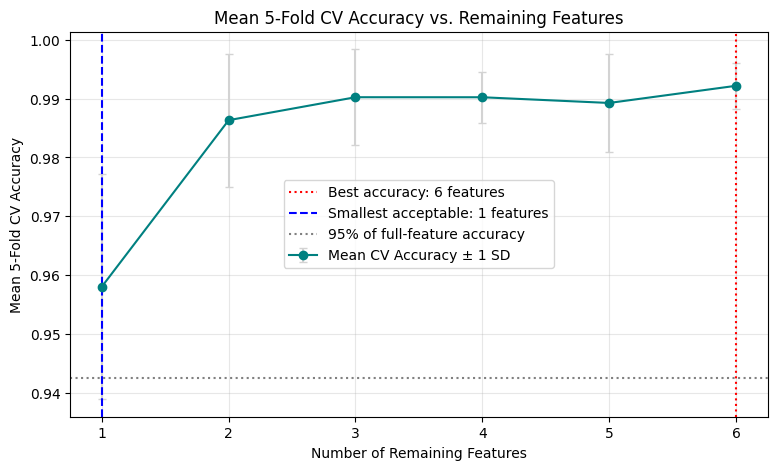

In [63]:
# Plot accuracy vs. number of remaining features
plt.figure(figsize=(9, 5))
plt.errorbar(
    B3_plot_features,
    B3_plot_accuracy,
    yerr=B3_plot_std,
    fmt='-o',
    color='teal',
    ecolor='lightgray',
    capsize=3,
    label='Mean CV Accuracy ± 1 SD'
)
plt.axvline(
    B3_optimal_num_features,
    color='red',
    linestyle=':',
    label=f'Best accuracy: {B3_optimal_num_features} features'
)
plt.axvline(
    B3_essential_num_features,
    color='blue',
    linestyle='--',
    label=f'Smallest acceptable: {B3_essential_num_features} features'
)
plt.axhline(
    B3_metadata['threshold_accuracy'],
    color='gray',
    linestyle=':',
    label='95% of full-feature accuracy'
)
plt.xlabel('Number of Remaining Features')
plt.ylabel('Mean 5-Fold CV Accuracy')
plt.title('Mean 5-Fold CV Accuracy vs. Remaining Features')
plt.xticks(B3_plot_features)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

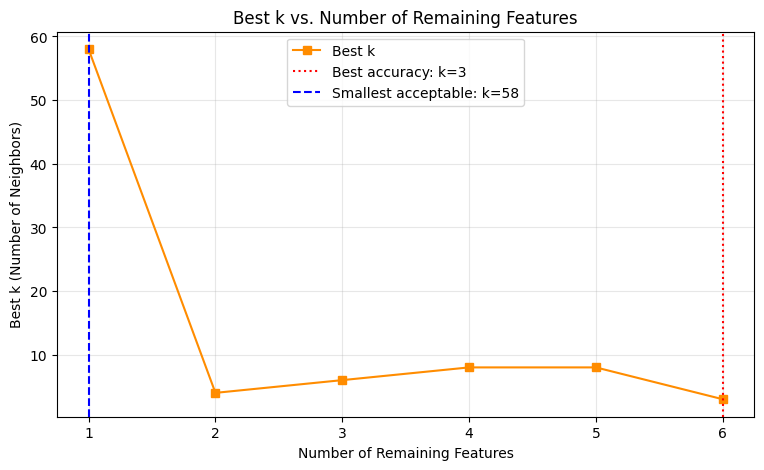

In [64]:
# Plot best k vs. number of remaining features
plt.figure(figsize=(9, 5))
plt.plot(
    B3_plot_features,
    B3_plot_k,
    marker='s',
    color='darkorange',
    label='Best k'
)
plt.axvline(
    B3_optimal_num_features,
    color='red',
    linestyle=':',
    label=f'Best accuracy: k={B3_optimal_k}'
)
plt.axvline(
    B3_essential_num_features,
    color='blue',
    linestyle='--',
    label=f'Smallest acceptable: k={B3_essential_k}'
)
plt.xlabel('Number of Remaining Features')
plt.ylabel('Best k (Number of Neighbors)')
plt.title('Best k vs. Number of Remaining Features')
plt.xticks(B3_plot_features)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The removal order is `height_left`, `diagonal`, `height_right`, `margin_up`, and `margin_low`, leaving `length` as the final feature. After each removal, I use a pipeline to standardize the remaining features within each cross-validation training fold and evaluate KNN. All five removals satisfy the accuracy threshold, so **the process stops when only one feature remains**.

The **full-feature** model achieves the highest accuracy of **0.992185557**, while the one-feature model achieves **0.958034433**. The error bars represent ±1 standard deviation of accuracy across the five validation folds.

With all **six features**, the best k is **3**. As features are removed, the best k changes **between 4 and 8**, before increasing to **58** when only `length` remains.

The smallest subset meeting the 95% accuracy threshold contains **one feature**: `length`. The threshold is **0.942576279**, calculated as 95% of the full-feature accuracy. The one-feature model achieves **0.958034433**, which is above this threshold. Therefore, `length` alone is sufficient to meet the required accuracy criterion.

The highest mean cross-validation accuracy is **0.992185557 (99.22%)**, achieved with **all six features** and **k = 3**. This is the best-performing model in the **tree-based selection process**.

**Performance & Retained Features:** In Part B2, forward selection achieves a highest mean CV accuracy of **0.992195122** using **five features** with **k = 6**. In Part B3, the highest accuracy is **0.992185557** using **all six features** with **k = 3**. The two methods achieve nearly identical best accuracies, but **forward selection achieves a slightly higher score using one fewer feature**.

**Methodological Differences:**

Forward selection starts with an empty feature set and adds the feature that produces the highest KNN validation accuracy at each step. Tree-based selection starts with all features and removes them according to their importance in a decision tree. The difference of performance is reasonable because the methods use different selection rules, they can identify different feature subsets. And Features important to a decision tree may not be the most useful for KNN.

In addition, the two methods evaluate different feature combinations. Forward selection identifies a five-feature subset that excludes 'height_right', while the tree-based method first removes 'height_left'. Therefore, the tree-based method does not evaluate the same five-feature subset.

The difference in their highest mean CV accuracies is only 0.000009565, so their classification performance is practically identical. This small difference is not sufficient to conclude that forward selection is statistically better.

# Part B4: PCA-based Dimensionality Reduction

Instead of selecting or removing individual features, PCA transforms features into a new set of uncorrelated variables called principal components. These components are ordered according to how much variance in the original data they explain.

We will vary n_components (number of principal components retained), then train and tune a KNN classifier on the transformed data using 5-fold cross-validation.

1. Sweep the number of principal components from 1 to the total number of original features. For each number of principal components, train a KNN classifier using 5-fold cross-validation and tune k from 1 to 100 with a step size of 1.

2. Plot the best mean cross-validation accuracy (y-axis) vs. the number of principal components (x-axis).

3. Plot the corresponding best k (y-axis) vs. the number of principal components (x-axis).

In [65]:
from sklearn.decomposition import PCA

# Define the number of principal components and k range
B4_n_components_range = range(1, X_train.shape[1] + 1)
B4_k_range = range(1, 101)

B4_accuracy = []
B4_best_k = []
B4_std = []

# Evaluate KNN with different numbers of principal components
for n_components in B4_n_components_range:
    best_accuracy = -1
    best_k = None
    best_std = None

    for k in B4_k_range:
        model = make_pipeline(
            preprocessing.StandardScaler(),
            PCA(n_components=n_components),
            neighbors.KNeighborsClassifier(
                n_neighbors=k, n_jobs=-1
            )
        )

        scores = cross_val_score(
            model, X_train, y_train,
            cv=5,
            scoring='accuracy',
            n_jobs=-1
        )

        mean_accuracy = scores.mean()

        if mean_accuracy > best_accuracy:
            best_accuracy = mean_accuracy
            best_k = k
            best_std = scores.std()

    B4_accuracy.append(best_accuracy)
    B4_best_k.append(best_k)
    B4_std.append(best_std)

    print(
        f'n_components: {n_components}; '
        f'Best k: {best_k}; '
        f'Highest Mean CV Accuracy: {best_accuracy:.9f} '
        f'(±{best_std:.9f})'
    )

n_components: 1; Best k: 42; Highest Mean CV Accuracy: 0.981434720 (±0.008429320)
n_components: 2; Best k: 76; Highest Mean CV Accuracy: 0.981439503 (±0.010430200)
n_components: 3; Best k: 15; Highest Mean CV Accuracy: 0.983390722 (±0.006645225)
n_components: 4; Best k: 9; Highest Mean CV Accuracy: 0.988287901 (±0.009043827)
n_components: 5; Best k: 14; Highest Mean CV Accuracy: 0.990234338 (±0.005343669)
n_components: 6; Best k: 3; Highest Mean CV Accuracy: 0.992185557 (±0.003907265)


In [66]:
# Find the optimal number of principal components
best_index = np.argmax(B4_accuracy)

B4_optimal_n_components = B4_n_components_range[best_index]
B4_optimal_accuracy = B4_accuracy[best_index]
B4_optimal_k = B4_best_k[best_index]

print(f'Optimal Number of Principal Components: {B4_optimal_n_components}')
print(f'Highest Mean CV Accuracy: {B4_optimal_accuracy:.9f}')
print(f'Corresponding Best k: {B4_optimal_k}')

Optimal Number of Principal Components: 6
Highest Mean CV Accuracy: 0.992185557
Corresponding Best k: 3


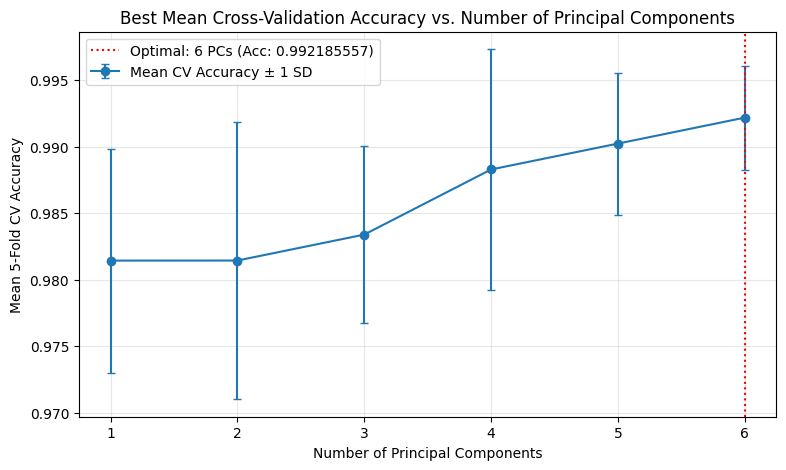

In [67]:
# Plot accuracy vs. number of principal components
plt.figure(figsize=(9, 5))
plt.errorbar(
    B4_n_components_range,
    B4_accuracy,
    yerr=B4_std,
    fmt='-o',
    capsize=3,
    label='Mean CV Accuracy ± 1 SD'
)
plt.axvline(
    B4_optimal_n_components,
    color='red',
    linestyle=':',
    label=f'Optimal: {B4_optimal_n_components} PCs '
          f'(Acc: {B4_optimal_accuracy:.9f})'
)
plt.xlabel('Number of Principal Components')
plt.ylabel('Mean 5-Fold CV Accuracy')
plt.title('Best Mean Cross-Validation Accuracy vs. Number of Principal Components')
plt.xticks(B4_n_components_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

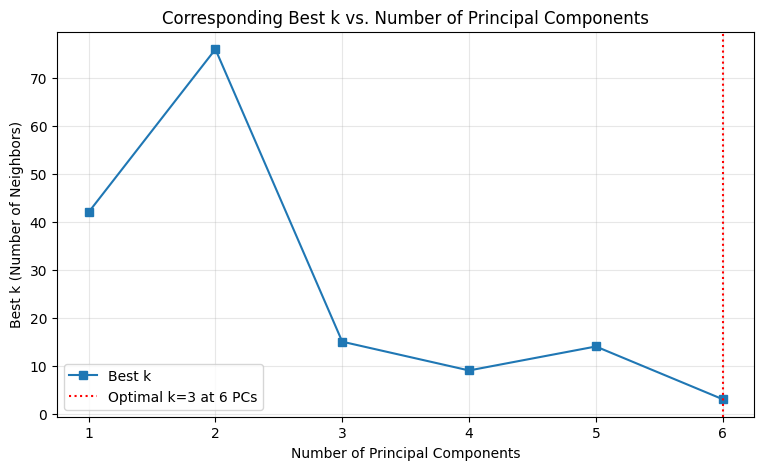

In [68]:
# Plot best k vs. number of principal components
plt.figure(figsize=(9, 5))
plt.plot(
    B4_n_components_range,
    B4_best_k,
    marker='s',
    label='Best k'
)
plt.axvline(
    B4_optimal_n_components,
    color='red',
    linestyle=':',
    label=f'Optimal k={B4_optimal_k} '
          f'at {B4_optimal_n_components} PCs'
)
plt.xlabel('Number of Principal Components')
plt.ylabel('Best k (Number of Neighbors)')
plt.title('Corresponding Best k vs. Number of Principal Components')
plt.xticks(B4_n_components_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The mean accuracy generally increases as more components are retained, from **0.981434720** with one component to **0.992185557** with six components. The improvement between one and two components is very small, while the accuracy increases more noticeably with four or more components.

The best k values are 42, 76, 15, 9, 14, and 3 for one to six components, respectively. The optimal k generally becomes **smaller** as more components are retained, although it does not decrease consistently. This indicates that the most suitable neighborhood size depends on the number of principal components.

The optimal number of principal components is **6**, achieving the highest mean CV accuracy of **0.992185557 (99.22%)**, with **k = 3**.

PCA provides moderately effective dimensionality reduction for this dataset. For example, retaining four principal components reduces the dimensionality by **33.3%** while achieving a mean CV accuracy of **0.988287901 (98.83%)**. Using five components achieves **0.990234338 (99.02%)**. However, the highest accuracy requires all six components, so **PCA does not reduce dimensionality without some loss in accuracy**.

Compared with Part B2, forward selection achieves a slightly higher mean CV accuracy of 0.992195122 using only five original features, while PCA achieves 0.992185557 using all six components. Forward selection also retains the original feature measurements, which are easier to interpret. Therefore, **forward selection appears more suitable for this dataset** when considering both classification accuracy and the number of retained dimensions, although the difference in accuracy is very small.

# Part C: Other Built-in Models & Hyperparameter Tuning

In this part, we will use some built-in models, and tune their hyperparameters to achieve high accuracy/scores.

The models are:

1. Decision Tree (Part C1)
2. Random Forest (Part C2)
3. Bagged Trees (Part C3)

# Part C1: Decision Tree Classifier

Train and tune a decision tree classifier on the standardized full feature training set. Tune the two hypermarameters `max_depth` and `min_samples_split` using `RandomizedSearchCV` with `n_iter=500`, `'max_depth': randint(1, 10)`, `'min_samples_split': randint(2, 50)`.
  
Configure RandomizedSearchCV with the following settings: `cv=5`, `verbose=2`, `random_state=42`, `n_jobs=-1`, `return_train_score=True`.


In [69]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [70]:
# Define hyperparameter search ranges
C1_param_dist = {
    'decisiontreeclassifier__max_depth': randint(1, 10),
    'decisiontreeclassifier__min_samples_split': randint(2, 50)
}

In [71]:
# Build Decision Tree pipeline
C1_model = make_pipeline(
    preprocessing.StandardScaler(),
    DecisionTreeClassifier(random_state=42)
)

In [72]:
# Hyperparameter tuning with 5-fold CV
C1_search = RandomizedSearchCV(
    estimator=C1_model,
    param_distributions=C1_param_dist,
    n_iter=500,
    cv=5,
    scoring='accuracy',
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

C1_search.fit(X_train, y_train)

Fitting 5 folds for each of 500 candidates, totalling 2500 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('standardscaler',
                                              StandardScaler()),
                                             ('decisiontreeclassifier',
                                              DecisionTreeClassifier(random_state=42))]),
                   n_iter=500, n_jobs=-1,
                   param_distributions={'decisiontreeclassifier__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x78498ab401a0>,
                                        'decisiontreeclassifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7849825dee90>},
                   random_state=42, return_train_score=True, scoring='accuracy',
                   verbose=2)

In [73]:
# Collect the best model and results
C1_best_model = C1_search.best_estimator_
C1_best_accuracy = C1_search.best_score_
C1_best_params = C1_search.best_params_

C1_best_max_depth = C1_best_params['decisiontreeclassifier__max_depth']
C1_best_min_samples_split = C1_best_params['decisiontreeclassifier__min_samples_split']

print(
    f'Best performance using decision tree is {C1_best_accuracy:.9f} '
    f'with a max depth of {C1_best_max_depth} '
    f'and a min samples split of {C1_best_min_samples_split}.'
)

Best performance using decision tree is 0.982439024 with a max depth of 5 and a min samples split of 3.


# Part C2: Random Forests

Train and tune a Random Forest classifier on the standardized full feature training set. Tune the two hyperparameters `n_estimators` and `max_features` using `RandomizedSearchCV` with `n_iter=500`, set: `max_features : ['sqrt', 'log2', 0.1, 0.25, 0.5]`, `n_estimators : randint(10, 200)`.

For RandomizedSearchCV, use: `cv=5`, `verbose=2`, `random_state=42`, `n_jobs=-1`.

In [74]:
from sklearn.ensemble import RandomForestClassifier

In [75]:
# Define hyperparameter search ranges
C2_param_dist = {
    'randomforestclassifier__max_features': [
        'sqrt', 'log2', 0.1, 0.25, 0.5
    ],
    'randomforestclassifier__n_estimators': randint(10, 200)
}

In [76]:
# Build Random Forest pipeline
C2_model = make_pipeline(
    preprocessing.StandardScaler(),
    RandomForestClassifier(random_state=42)
)

In [77]:
# Hyperparameter tuning with 5-fold CV
C2_search = RandomizedSearchCV(
    estimator=C2_model,
    param_distributions=C2_param_dist,
    n_iter=500,
    cv=5,
    scoring='accuracy',
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

C2_search.fit(X_train, y_train)

Fitting 5 folds for each of 500 candidates, totalling 2500 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('standardscaler',
                                              StandardScaler()),
                                             ('randomforestclassifier',
                                              RandomForestClassifier(random_state=42))]),
                   n_iter=500, n_jobs=-1,
                   param_distributions={'randomforestclassifier__max_features': ['sqrt',
                                                                                 'log2',
                                                                                 0.1,
                                                                                 0.25,
                                                                                 0.5],
                                        'randomforestclassifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x78497e264550>},
                   random_state=42, return_train_score=True, scoring='accuracy',
                   verbose=2)

In [78]:
# Collect the best model and results
C2_best_model = C2_search.best_estimator_
C2_best_accuracy = C2_search.best_score_
C2_best_params = C2_search.best_params_

C2_best_n_estimators = C2_best_params[
    'randomforestclassifier__n_estimators'
]
C2_best_max_features = C2_best_params[
    'randomforestclassifier__max_features'
]

print(
    f'Best n_estimators: {C2_best_n_estimators}, '
    f'Best Max Features: {C2_best_max_features}, '
    f'Best Accuracy: {C2_best_accuracy:.9f}'
)

Best n_estimators: 81, Best Max Features: 0.1, Best Accuracy: 0.991219512


# Part C3: Bagging (ensemble of bagged trees)

Similarly, train and tune a bagging classifier on the standardized full feature training set. Set `max_features` to the total number of features in the dataset and use `bootstrap=True`.

Then tune the hyperparameter `n_estimators` using 5-fold cross-validation (CV) with: `n_estimators = [10, 50, 100, 200]`.

In [80]:
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import GridSearchCV

In [81]:
# Define hyperparameter search range
C3_total_features = X_train.shape[1]

C3_param_grid = {
    'baggingclassifier__n_estimators': [10, 50, 100, 200]
}

In [82]:
# Build Bagging Classifier pipeline
C3_model = make_pipeline(
    preprocessing.StandardScaler(),
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        max_features=C3_total_features,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )
)

In [83]:
# Hyperparameter tuning with 5-fold CV
C3_search = GridSearchCV(
    estimator=C3_model,
    param_grid=C3_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    return_train_score=True
)

C3_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('baggingclassifier',
                                        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                                                          max_features=6,
                                                          n_jobs=-1,
                                                          random_state=42))]),
             n_jobs=-1,
             param_grid={'baggingclassifier__n_estimators': [10, 50, 100, 200]},
             return_train_score=True, scoring='accuracy')

In [84]:
# Collect the best model and results
C3_best_model = C3_search.best_estimator_
C3_best_accuracy = C3_search.best_score_
C3_best_params = C3_search.best_params_

C3_best_n_estimators = C3_best_params[
    'baggingclassifier__n_estimators'
]

print(
    f'Best n_estimators (Bagged Trees): {C3_best_n_estimators}, '
    f'Best Accuracy (Bagged Trees): {C3_best_accuracy:.9f}.'
)

Best n_estimators (Bagged Trees): 100, Best Accuracy (Bagged Trees): 0.985361071.


# Part D: Report the accuracy of all your tuned models

So far we have developed 4 models, these models are:

1. The Tuned Decision Tree (from Part C)
2. The Tuned Random Forest (from Part C)
3. The Tuned Bagged Trees (from Part C)
4. Best model in Part B, including the three feature selection method

In [89]:
# Collect the optimal Forward Selection results from B2
D_forward_index = np.argmax(B2_accuracy)

D_forward_accuracy = B2_accuracy[D_forward_index]
D_forward_k = B2_best_k[D_forward_index]
D_forward_features = B2_selected_features[D_forward_index]
D_forward_num_features = len(D_forward_features)

In [90]:
# Collect model performance
D_model_comparison = {
    'Model': [
        'Decision Tree',
        'Random Forest',
        'Bagged Trees',
        'KNN (Forward Selection)'
    ],
    'Features': [
        X_train.shape[1],
        X_train.shape[1],
        X_train.shape[1],
        D_forward_num_features
    ],
    'Best Hyperparameters': [
        f'max_depth={C1_best_max_depth}, '
        f'min_samples_split={C1_best_min_samples_split}',

        f'n_estimators={C2_best_n_estimators}, '
        f'max_features={C2_best_max_features}',

        f'n_estimators={C3_best_n_estimators}, '
        f'max_features={C3_total_features}',

        f'k={D_forward_k}'
    ],
    'Mean CV Accuracy': [
        C1_best_accuracy,
        C2_best_accuracy,
        C3_best_accuracy,
        D_forward_accuracy
    ]
}

In [91]:
# Create and sort the comparison table
D_comparison_df = pd.DataFrame(D_model_comparison)

D_comparison_df = (
    D_comparison_df
    .sort_values('Mean CV Accuracy', ascending=False)
    .reset_index(drop=True)
)

In [92]:
# Display the results
display(
    D_comparison_df.style
    .format({'Mean CV Accuracy': '{:.9f}'})
    .highlight_max(
        subset=['Mean CV Accuracy'],
        color='#d9ead3'
    )
    .set_caption('Part D: Best Model Cross-Validation Performance')
    .set_properties(**{'text-align': 'left'})
)

,Model,Features,Best Hyperparameters,Mean CV Accuracy
0,KNN (Forward Selection),5,k=6,0.992195122
1,Random Forest,6,"n_estimators=81, max_features=0.1",0.991219512
2,Bagged Trees,6,"n_estimators=100, max_features=6",0.985361071
3,Decision Tree,6,"max_depth=5, min_samples_split=3",0.982439024


In [93]:
# Identify the best-performing model
D_best_model_name = D_comparison_df.loc[0, 'Model']
D_best_cv_score = D_comparison_df.loc[0, 'Mean CV Accuracy']

print(f'Best model: {D_best_model_name}')
print(f'Highest mean CV accuracy: {D_best_cv_score:.9f}')

Best model: KNN (Forward Selection)
Highest mean CV accuracy: 0.992195122


The KNN model using **Forward Selection** achieves the highest mean CV accuracy of **0.992195122 (99.22%)** with **five** selected features and **k = 6**. **Random Forest** ranks second with an accuracy of **0.991219512 (99.12%)**, followed by **Bagged Trees** at **0.985361071 (98.54%)** and **Decision Tree** at **0.982439024 (98.24%)**.

Based on these cross-validation results, **forward-selected KNN** is the best-performing model among the four evaluated approaches. However, the differences are relatively **small**, and final performance on unseen data still needs to be evaluated using the held-out test set in Part E.

# Part E: Evaluation on Test Data

### Part E1: Performance measures
Pick the best model (highest accuracy) and apply it to the test set.

Compute the following using the standardized test data:
1. accuracy,
2. precision,
3. recall,
4. Fall-out rate,
5. F1 score,
6. confusion matrix

In [94]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

In [95]:
# Retrieve the best Forward Selection results from B2
E1_best_index = np.argmax(B2_accuracy)
E1_best_features = B2_selected_features[E1_best_index]
E1_best_k = B2_best_k[E1_best_index]

In [96]:
# Build the optimal KNN model
E1_best_model = make_pipeline(
    preprocessing.StandardScaler(),
    neighbors.KNeighborsClassifier(
        n_neighbors=E1_best_k,
        n_jobs=-1
    )
)

In [97]:
# Fit the model and predict on the test set
E1_best_model.fit(X_train[E1_best_features], y_train)

E1_y_test_pred = E1_best_model.predict(
    X_test[E1_best_features]
)

In [98]:
# Calculate the confusion matrix
# 0 = Counterfeit, 1 = Genuine
E1_cm = confusion_matrix(
    y_test, E1_y_test_pred, labels=[0, 1]
)

E1_tn, E1_fp, E1_fn, E1_tp = E1_cm.ravel()

In [99]:
# Calculate performance metrics
E1_test_accuracy = accuracy_score(y_test, E1_y_test_pred)

E1_test_precision = precision_score(
    y_test, E1_y_test_pred, pos_label=1
)

E1_test_recall = recall_score(
    y_test, E1_y_test_pred, pos_label=1
)

E1_test_fallout = E1_fp / (E1_fp + E1_tn)

E1_test_f1 = f1_score(
    y_test, E1_y_test_pred, pos_label=1
)

In [100]:
# Display results
print(f"1. Accuracy:       {E1_test_accuracy:.9f}")
print(f"2. Precision:      {E1_test_precision:.9f}")
print(f"3. Recall:         {E1_test_recall:.9f}")
print(f"4. Fall-out Rate:  {E1_test_fallout:.9f}")
print(f"5. F1 Score:       {E1_test_f1:.9f}")
print("6. Confusion Matrix (0=Fake, 1=Genuine):")
print(E1_cm)
print(
    f"(TN={E1_tn}, FP={E1_fp}, "
    f"FN={E1_fn}, TP={E1_tp})"
)

1. Accuracy:       0.988610478
2. Precision:      0.986710963
3. Recall:         0.996644295
4. Fall-out Rate:  0.028368794
5. F1 Score:       0.991652755
6. Confusion Matrix (0=Fake, 1=Genuine):
[[137   4]
 [  1 297]]
(TN=137, FP=4, FN=1, TP=297)


1. Accuracy (**0.988610478**): Accuracy measures the proportion of correctly classified banknotes. The model correctly classifies 434 out of 439 test banknotes, achieving an accuracy of 98.86%.

2. Precision (**0.986710963**): Precision measures the proportion of banknotes predicted as genuine that are actually genuine. Of the 301 banknotes predicted as genuine, 297 are correctly classified, giving a precision of 98.67%.

3. Recall (**0.996644295**): Recall measures the proportion of actual genuine banknotes correctly identified as genuine. The model correctly identifies 297 out of 298 genuine banknotes, achieving a recall of 99.66%.

4. Fall-out Rate (**0.028368794**): Fall-out rate is the false positive rate. It measures the proportion of counterfeit banknotes incorrectly classified as genuine. The model incorrectly accepts 4 out of 141 counterfeit banknotes, giving a fall-out rate of 2.84%.

5. F1 Score (**0.991652755**): The F1 score is the harmonic mean of precision and recall. The score of 99.17% indicates that the model achieves both high precision and high recall when identifying genuine banknotes.

6. Confusion Matrix: The confusion matrix is **[[137, 4], [1, 297]]**, where **TN = 137, FP = 4, FN = 1, and TP = 297**. The model correctly classifies 137 counterfeit banknotes and 297 genuine banknotes. It incorrectly identifies four counterfeit banknotes as genuine and one genuine banknote as counterfeit.

Overall, the model achieves high classification accuracy on the held-out test set. It correctly identifies most genuine and counterfeit banknotes, although a small number of classification errors remain.

# Part E2: ROC and AUC

In [101]:
from sklearn.metrics import roc_curve, roc_auc_score

In [102]:
# Predict probabilities using the best model from E1
E2_y_test_proba = E1_best_model.predict_proba(
    X_test[E1_best_features]
)[:, 1]

In [103]:
# Compute ROC curve and AUC
E2_fpr, E2_tpr, E2_thresholds = roc_curve(
    y_test, E2_y_test_proba, pos_label=1
)

E2_auc = roc_auc_score(y_test, E2_y_test_proba)

print(f"Test ROC AUC Score: {E2_auc:.9f}")

Test ROC AUC Score: 0.990777762


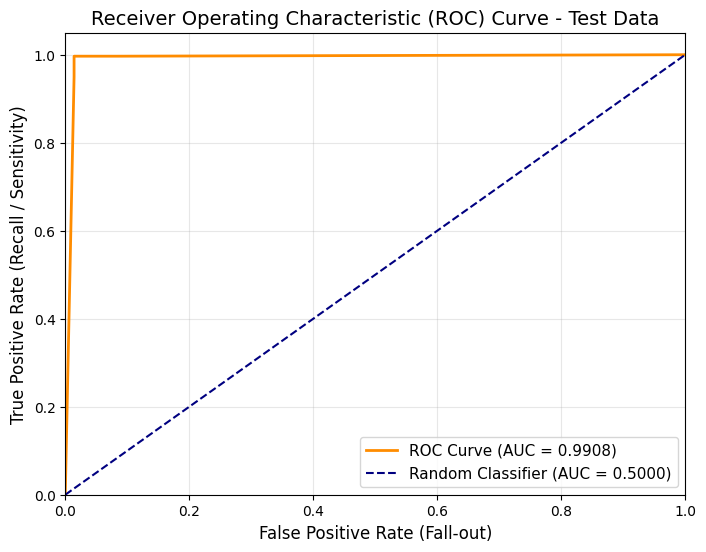

In [104]:
# Plot the ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    E2_fpr,
    E2_tpr,
    color='darkorange',
    lw=2,
    label=f'ROC Curve (AUC = {E2_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    lw=1.5,
    linestyle='--',
    label='Random Classifier (AUC = 0.5000)'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Fall-out)', fontsize=12)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve - Test Data', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

For the AUC: The test ROC AUC is **0.990777762** (approximately 99.08%). This means there is approximately a 99.08% probability that a randomly selected genuine banknote receives a higher predicted genuine score than a randomly selected counterfeit banknote, with ties counted as half.

The ROC curve is **close to the upper-left corner**, indicating that the model achieves **high genuine-banknote recall** while maintaining a **low false positive rate** across suitable classification thresholds. Overall, the high AUC indicates strong discrimination between genuine and counterfeit banknotes on the test set.